In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle, ConnectionPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.colors import LinearSegmentedColormap

In [2]:
#parameters plot
def plot_params(fontsize=18, tick_labelsize=12, legend_fontsize=18):
    """
    Update the parameters of the plot.

    Returns
    -------
    cmap : string
        The color map used in the colored plots.
    """
    plt.clf()
    plt.rc('font', size=fontsize)
    plt.rc('xtick', labelsize=tick_labelsize)
    plt.rc('ytick', labelsize=tick_labelsize)
    plt.rc('legend', fontsize=legend_fontsize)
    plt.rc('text', usetex=True)
    font = {'family' : 'stix'}
    plt.rc('font', **font)
    plt.rcParams["mathtext.fontset"] = "stix"
    mpl.rcParams['axes.linewidth'] = 1.3 #set the value globally
    plt.rc('xtick.major', size=8, width=1.3)
    plt.rc('ytick.major', size=8, width=1.3)

In [3]:
bif_x_indo = pd.read_csv("bif_indo_x.dat", sep=r"\s+", header=None, names=["b", "x_max"])
bif_x_voltando = pd.read_csv("bif_voltando_x.dat", sep=r"\s+", header=None, names=["b", "x_max"])

bif_y_indo = pd.read_csv("bif_indo_y.dat", sep=r"\s+", header=None, names=["b", "y_max"])
bif_y_voltando = pd.read_csv("bif_voltando_y.dat", sep=r"\s+", header=None, names=["b", "y_max"])

bif_z_indo = pd.read_csv("bif_indo_z.dat", sep=r"\s+", header=None, names=["b", "z_max"])
bif_z_voltando = pd.read_csv("bif_voltando_z.dat", sep=r"\s+", header=None, names=["b", "z_max"])

<Figure size 640x480 with 0 Axes>

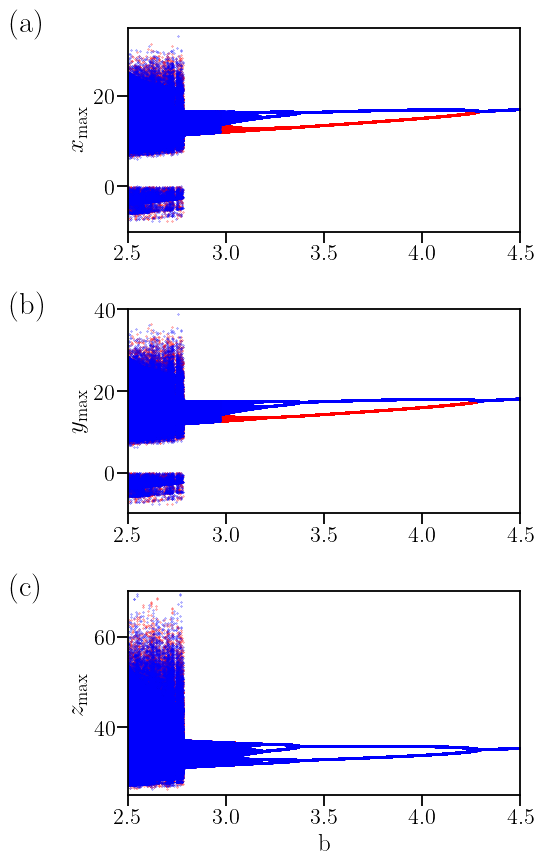

In [8]:
plot_params(fontsize=18, tick_labelsize=16, legend_fontsize=18)

fig, ax = plt.subplots(3, 1, figsize=(6,9))

#########figura a
ax[0].plot(bif_x_indo['b'],bif_x_indo['x_max'],'.',ms=0.5,color='red')
ax[0].plot(bif_x_voltando['b'],bif_x_voltando['x_max'],'.',ms=0.5,color='blue')
ax[0].set_xlim(2.5,4.5)
ax[0].set_ylim(-10,35)
#ax[0].set_yticks(np.arange(-14,-1,4))
#ax[0].set_xticks(np.arange(0.1,1.01,0.25))
#ax[0].set_xticks([0.1,0.35,0.60,0.85, 1])
ax[0].set_xlabel(r"")
ax[0].set_ylabel(r"$x_{\rm max}$", color='black')
ax[0].text(-0.3,0.98,r"(a)",transform=ax[0].transAxes,fontsize=22,fontweight="bold")

#########figura b
ax[1].plot(bif_y_indo['b'],bif_y_indo['y_max'],'.',ms=0.5,color='red')
ax[1].plot(bif_y_voltando['b'],bif_y_voltando['y_max'],'.',ms=0.5,color='blue')
ax[1].set_xlim(2.5,4.5)
ax[1].set_ylim(-10,40)
#ax[0].set_yticks(np.arange(-14,-1,4))
#ax[0].set_xticks(np.arange(0.1,1.01,0.25))
#ax[0].set_xticks([0.1,0.35,0.60,0.85, 1])
ax[1].set_xlabel(r"")
ax[1].set_ylabel(r"$y_{\rm max}$", color='black')
ax[1].text(-0.3,0.98,r"(b)",transform=ax[1].transAxes,fontsize=22,fontweight="bold")

#########figura c
ax[2].plot(bif_z_indo['b'],bif_z_indo['z_max'],'.',ms=0.5,color='red')
ax[2].plot(bif_z_voltando['b'],bif_z_voltando['z_max'],'.',ms=0.5,color='blue')
ax[2].set_xlim(2.5,4.5)
ax[2].set_ylim(25,70)
#ax[0].set_yticks(np.arange(-14,-1,4))
#ax[0].set_xticks(np.arange(0.1,1.01,0.25))
#ax[0].set_xticks([0.1,0.35,0.60,0.85, 1])
ax[2].set_xlabel(r"b")
ax[2].set_ylabel(r"$z_{\rm max}$", color='black')
ax[2].text(-0.3,0.98,r"(c)",transform=ax[2].transAxes,fontsize=22,fontweight="bold")
####################################
####################################
####################################
ax[0].tick_params(axis='x', pad=1)
ax[0].tick_params(axis='y', pad=1)
ax[1].tick_params(axis='x', pad=1)
ax[1].tick_params(axis='y', pad=1)
ax[2].tick_params(axis='x', pad=1)
ax[2].tick_params(axis='y', pad=1)

# Ajuste fino
pos0 = ax[0].get_position()
ax[0].set_position([pos0.x0, pos0.y0, pos0.width, pos0.height])
pos1 = ax[1].get_position()
ax[1].set_position([pos1.x0, pos1.y0, pos1.width, pos1.height])
pos2 = ax[2].get_position()
ax[2].set_position([pos2.x0, pos2.y0, pos2.width, pos2.height])
####################################
# SAVE
####################################

plt.tight_layout()
plt.savefig("fig2.jpeg",format="jpeg",dpi=600,bbox_inches="tight")
plt.show()

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Let's simulate the floating point rounding issue that creates a vertical white line.
# Suppose phi has a grid from 0 to 1 with step 0.01, but at phi=0.5, half the points are 0.5000001 and half are 0.4999999.
phi = np.arange(0, 1.01, 0.05)
alpha = np.arange(0, 3.01, 0.1)

PH, AL = np.meshgrid(phi, alpha)
df = pd.DataFrame({'phi': PH.flatten(), 'alpha': AL.flatten()})
df['l1'] = np.sin(df['phi']) * np.cos(df['alpha'])
df['l2'] = df['l1']

# Introduce floating point noise at phi = 0.5
df.loc[(df['phi'] == 0.5) & (df['alpha'] > 1.5), 'phi'] = 0.5000004
df.loc[(df['phi'] == 0.5) & (df['alpha'] <= 1.5), 'phi'] = 0.4999996

# Apply the user's rounding to 6 decimals
df['phi'] = df['phi'].round(6)
df['alpha'] = df['alpha'].round(6)

# Pivot table like user's function
pivot = df.pivot_table(index='alpha', columns='phi', values='l1', aggfunc='first')
print("Unique phi values near 0.5:", pivot.columns[(pivot.columns > 0.48) & (pivot.columns < 0.52)].values)
print("NaN count in these columns:\n", pivot.isna().sum())

Unique phi values near 0.5: [0.5]
NaN count in these columns:
 phi
0.00    0
0.05    0
0.10    0
0.15    0
0.20    0
0.25    0
0.30    0
0.35    0
0.40    0
0.45    0
0.50    0
0.55    0
0.60    0
0.65    0
0.70    0
0.75    0
0.80    0
0.85    0
0.90    0
0.95    0
1.00    0
dtype: int64


KeyError: 'l1'

<Figure size 640x480 with 0 Axes>

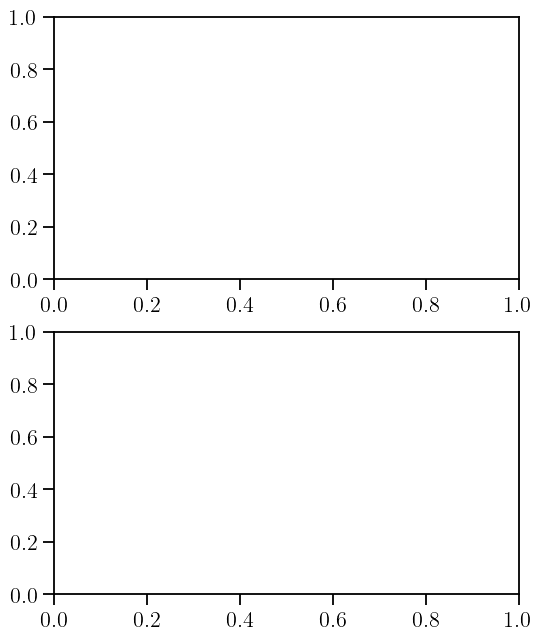

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap

# ======================================================
# Função de estilo (caso você já tenha a sua)
# ======================================================

plot_params(fontsize=18, tick_labelsize=16, legend_fontsize=18)

fig, ax = plt.subplots(2, 1, figsize=(6,7.5))

# ======================================================
# Substitui l1 por l2 quando l1 ~ 0
# ======================================================

eps = 1e-5

alfa2["lambda_plot"] = np.where(
    np.abs(alfa2["l1"]) < eps,
    alfa2["l2"],
    alfa2["l1"]
)

alfa05["lambda_plot"] = np.where(
    np.abs(alfa05["l1"]) < eps,
    alfa05["l2"],
    alfa05["l1"]
)

# ======================================================
# Paleta semelhante à do gnuplot
# ======================================================

vals = np.array([
    -0.017,   # branco
    -0.015,   # azul
    -0.001,   # ciano
     0.000,   # preto
     0.001,   # amarelo
     0.050    # vermelho
])

vals = (vals - vals.min())/(vals.max()-vals.min())

colors = list(zip(
    vals,
    ['white','blue','cyan','black','yellow','red']
))

cmap = LinearSegmentedColormap.from_list(
    "lyap",
    colors
)

# ======================================================
# Função para construir matriz Z
# ======================================================

def dataframe_to_grid(df, xcol, ycol, zcol):

    x_unique = np.sort(df[xcol].unique())
    y_unique = np.sort(df[ycol].unique())

    pivot = df.pivot(
        index=ycol,
        columns=xcol,
        values=zcol
    )

    Z = pivot.values

    return x_unique, y_unique, Z

# ======================================================
# Dados figura (a)
# ======================================================

x1, y1, Z1 = dataframe_to_grid(
    alfa2,
    "phi",
    "varphi",
    "lambda_plot"
)

# ======================================================
# Dados figura (b)
# ======================================================

x2, y2, Z2 = dataframe_to_grid(
    alfa05,
    "phi",
    "varphi",
    "lambda_plot"
)

# ======================================================
# Limites da escala de cores
# ======================================================

vmin = -0.017
vmax = 0.05

# ======================================================
# Figura
# ======================================================

fig, ax = plt.subplots(
    2,
    1,
    figsize=(6, 7.5),
    sharex=True,
    sharey=True
)

# ======================================================
# Painel (a)
# ======================================================

pcm = ax[0].pcolormesh(
    x1,
    y1,
    Z1,
    shading="auto",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax
)

ax[0].set_xlim(0, 1)
ax[0].set_ylim(0, 1)

ax[0].set_xticks(np.arange(0, 1.01, 0.25))
ax[0].set_yticks(np.arange(0, 1.01, 0.25))

ax[0].set_ylabel(r"$\varphi$",rotation=0,labelpad=20,fontsize=20)

ax[0].text(
    0.35,
    1.03,
    r"$\xi = 0,\ \alpha = 2.0$",
    transform=ax[0].transAxes,
    fontsize=18,
    fontweight="bold"
)

ax[0].text(
    -0.22,
    1.1,
    "(a)",
    transform=ax[0].transAxes,
    fontsize=20,
    fontweight="bold"
)

# ======================================================
# Painel (b)
# ======================================================

ax[1].pcolormesh(
    x2,
    y2,
    Z2,
    shading="auto",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax
)

ax[1].set_xlim(0, 1)
ax[1].set_ylim(0, 1)

ax[1].set_xticks(np.arange(0, 1.01, 0.25))
ax[1].set_yticks(np.arange(0, 1.01, 0.25))

ax[1].set_xlabel(r"$\phi$")
ax[1].set_ylabel(r"$\varphi$",rotation=0,labelpad=20,fontsize=20)

ax[1].text(
    0.35,
    1.03,
    r"$\xi = 0,\ \alpha = 0.5$",
    transform=ax[1].transAxes,
    fontsize=18,
    fontweight="bold"
)

ax[1].text(
    -0.22,
    1.1,
    "(b)",
    transform=ax[1].transAxes,
    fontsize=20,
    fontweight="bold"
)

# ======================================================
# Colorbar horizontal no topo
# ======================================================


# [left, bottom, width, height]
cax = fig.add_axes([0.21, 0.96, 0.71, 0.025])

cbar = fig.colorbar(
    pcm,
    cax=cax,
    orientation='horizontal'
)

cbar.set_label(
    r"$\lambda$",
    fontsize=18
)

# ticks em cima
cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.xaxis.set_label_position('top')

# label
cbar.set_label(r'$\lambda$', fontsize=20)

cbar.set_ticks([-0.017, 0, 0.025, 0.05])

for a in ax:
    a.scatter(
        0.8, 0.95,
        marker='x',
        s=120,
        c='white',
        linewidths=3,
        zorder=10
    )

# ======================================================
# Ajustes finais
# ======================================================

for a in ax:
    a.tick_params(axis='x', pad=2)
    a.tick_params(axis='y', pad=2)

plt.tight_layout()

plt.savefig(
    "parameter_plane_lyapunov.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()